# Paper Example 2: Recovery of Known Parameters

This notebook walks through Example 2 of the PyTracerLab paper. Synthetic tritium
observations are generated with a known model, and the parameters are then inferred
from these observations with all four solvers of PyTracerLab:

- differential evolution (DE),
- least squares (LSQ) from ten random starting points,
- Metropolis-Hastings (MH) and DREAM (Markov chain Monte Carlo, MCMC).

Because the true parameters are known, the example shows how well each solver
recovers them, and how the MCMC samplers quantify the parameter uncertainty.

The script [`example_2.py`](https://github.com/iGW-TU-Dresden/PyTracerLab/blob/main/docs/examples/paper/example_2.py) produces the figures and numbers
of the paper, including the run times of the solvers. The full notebook takes a few
minutes to run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import PyTracerLab as lab

## 1. Synthetic Observations

The true model is a binary mixture of two dispersion model (DM) units: 20 % of the
water has a mean travel time of 2 yr, 80 % has 25 yr (dispersion parameter 0.1 for
both). The input is the semi-annual tritium time series of Example 3 of TracerLPM
(Jurgens et al., 2012), with a steady-state input of 6 TU before 1900.

Ten observations are taken at random dates from 1950 onwards and perturbed with
relative Gaussian noise of 5 %, i.e., each observation has its own uncertainty.

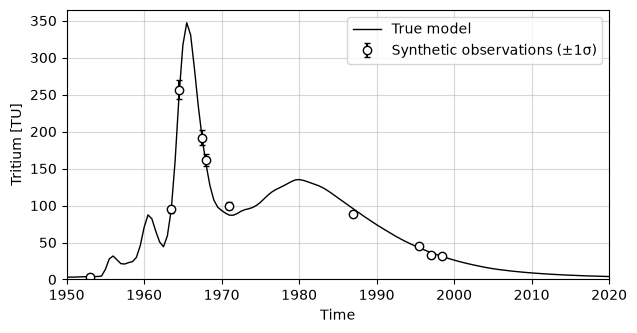

In [2]:
DT = 0.5  # semi-annual time steps (yr)
TRUE = {"dm1.mtt": 2.0, "dm1.DP": 0.1, "dm2.mtt": 25.0, "dm2.DP": 0.1, "dm1.fraction": 0.2}
NOISE_REL = 0.05  # relative noise of the observations (and assumed uncertainty)
SEED = 1234

inp = lab.read_series("tritium_input_semiannual.csv")
n = len(inp)
t_years = np.array([t.year + (t.month - 1) / 12 for t in inp.times])


def make_model(target=None, params=None, free_fraction=False):
    """Binary mixture of two DM units; the mixing fraction is fixed unless free_fraction."""
    params = params or {"dm1.mtt": 5.0, "dm1.DP": 0.5, "dm2.mtt": 50.0, "dm2.DP": 0.5}
    m = lab.Model(
        dt=DT,
        lambda_=lab.decay_constant("Tritium"),
        input_series=inp.values,
        target_series=target,
        steady_state_input=6.0,
        time_steps=inp.times,
    )
    bounds = [(1.0, 100.0), (0.001, 5.0)]  # mean travel time, dispersion parameter
    m.add_unit(
        lab.DMUnit(mtt=params["dm1.mtt"], DP=params["dm1.DP"]),
        fraction=TRUE["dm1.fraction"],
        prefix="dm1",
        bounds=bounds,
    )
    m.add_unit(
        lab.DMUnit(mtt=params["dm2.mtt"], DP=params["dm2.DP"]),
        fraction=1.0 - TRUE["dm1.fraction"],
        prefix="dm2",
        bounds=bounds,
    )
    if free_fraction:
        m.set_fixed("dm1.fraction", False)
        m.set_bounds("dm1.fraction", (0.0, 0.5))  # unit 1 is the smaller one
    return m


true_model = make_model(params=TRUE)
sim_true = true_model.simulate()

rng = np.random.default_rng(SEED)
idx = np.sort(np.random.RandomState(SEED).choice(np.arange(100, n), 10, replace=False))
obs = np.full(n, np.nan)  # observations on the time grid of the input, NaN = no sample
obs[idx] = sim_true[idx] * (1.0 + NOISE_REL * rng.standard_normal(len(idx)))

w = slice(100, n)  # 1950-2020
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t_years[w], sim_true[w], c="k", lw=1.0, label="True model")
ax.errorbar(t_years[idx], obs[idx], yerr=NOISE_REL * obs[idx], fmt="o", mfc="w", mec="k",
            ecolor="k", capsize=2, label="Synthetic observations (±1σ)")
ax.set(xlabel="Time", ylabel="Tritium [TU]", xlim=(1950, 2020), ylim=(0, None))
ax.grid(True, alpha=0.5)
ax.legend()
plt.show()

## 2. Calibration Model and Solver

The calibration model has the same structure, with different starting values. The
mean travel times and dispersion parameters of both units are calibrated (bounds
1-100 yr and 0.001-5); the mixing fraction is fixed at its true value (see
section 7 for a calibrated mixing fraction). All solvers use a relative measurement
uncertainty of 5 % (`sigma_rel=0.05`), i.e., the residuals are weighted with the
uncertainty of each observation.

In [3]:
m = make_model(target=obs)
solver = lab.Solver(m)
keys = m.param_keys(free_only=True)
print("Free parameters:", keys)


def chi2(sim):
    """Sum of squared weighted residuals."""
    return float(np.sum(((sim[idx] - obs[idx]) / (NOISE_REL * obs[idx])) ** 2))

Free parameters: ['dm1.DP', 'dm1.mtt', 'dm2.DP', 'dm2.mtt']


## 3. Differential Evolution

Differential evolution is a global optimiser: it searches the whole parameter space
within the bounds and does not need a starting point.

In [4]:
de_x, de_sim = solver.differential_evolution(
    maxiter=1000, popsize=20, random_state=42, sigma_rel=NOISE_REL
)
print({k: round(float(de_x[k]), 3) for k in keys}, " chi2 =", round(chi2(de_sim), 2))

{'dm1.DP': 0.12, 'dm1.mtt': 2.055, 'dm2.DP': 0.126, 'dm2.mtt': 26.044}  chi2 = 9.03


## 4. Least Squares from Ten Starting Points

Least squares is gradient-based and by far the fastest solver, but it finds the
optimum closest to its starting point. It is therefore started from ten random
points within the bounds.

In [5]:
lo, hi = np.array(m.get_bounds(free_only=True)).T
lsq = []
for start in rng.uniform(lo, hi, size=(10, len(keys))):
    for key, val in zip(keys, start):
        m.set_initial(key, val)
        m.set_param(key, val)
    try:
        x, s = solver.least_squares(sigma_rel=NOISE_REL)
    except (RuntimeError, ValueError) as err:  # no convergence
        print("Start", np.round(start, 2), "failed:", err)
        continue
    lsq.append((chi2(s), x, s))
lsq.sort(key=lambda r: r[0])
lsq_chi2, lsq_x, lsq_sim = lsq[0]
print("chi2 of all starts:", [round(r[0], 1) for r in lsq])
print("Best:", {k: round(float(lsq_x[k]), 3) for k in keys})

chi2 of all starts: [9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 614.3, 614.4, 614.6, 618.1]
Best: {'dm1.DP': 0.12, 'dm1.mtt': 2.055, 'dm2.DP': 0.126, 'dm2.mtt': 26.044}


Several starts end in a local optimum with a much poorer fit, in which the first unit
represents the older water. Started from enough points, least squares finds the same
solution as differential evolution.

## 5. Markov Chain Monte Carlo: Metropolis-Hastings and DREAM

The MCMC samplers draw samples from the posterior distribution of the parameters.
Both runs use the same number of model runs: MH with one chain of 32 000 steps
(half of them burn-in), DREAM with 8 chains of 4000 steps each (2000 burn-in).
DREAM moves chains that are stuck in a region of low posterior density to the best
chain during the burn-in (outlier chains). The Gelman-Rubin statistic
$\hat{R}$ should be close to 1 for all parameters; otherwise the chains have not
converged and the samples should not be used.

In [6]:
mh = solver.mcmc_sample(n_samples=8 * 2000, burn_in=8 * 2000, random_state=42, sigma_rel=NOISE_REL)
dream_kw = dict(n_samples=2000, burn_in=2000, n_chains=8, cr=[0.25, 0.5, 0.75, 1.0], return_sim=True,
                random_state=42)
dream = solver.dream_sample(**dream_kw, sigma_rel=NOISE_REL)
print("DREAM R-hat:", {k: round(float(v), 3) for k, v in dream["gelman_rubin"].items()})
print("Outlier chains moved during burn-in:", dream["n_outlier_resets"])

DREAM R-hat: {'dm1.DP': 1.019, 'dm1.mtt': 1.02, 'dm2.DP': 1.019, 'dm2.mtt': 1.015}
Outlier chains moved during burn-in: 2


## 6. Results

The table compares the estimates with the true values: DE and LSQ give a single best
fit, MH and DREAM the median and the 1-99 % interval of the posterior samples.

In [7]:
def quantiles(res, key):
    return np.quantile(res["samples"][:, res["param_names"].index(key)], [0.01, 0.5, 0.99])


print(f"{'parameter':10s} {'true':>6s} {'DE':>7s} {'LSQ':>7s}   {'MH median [1-99 %]':24s} DREAM median [1-99 %]")
for k in keys:
    row = f"{k:10s} {TRUE[k]:6.2f} {de_x[k]:7.3f} {lsq_x[k]:7.3f}"
    for res in (mh, dream):
        q = quantiles(res, k)
        row += f"   {q[1]:6.3f} [{q[0]:6.3f}, {q[2]:6.3f}]"
    print(row)

parameter    true      DE     LSQ   MH median [1-99 %]       DREAM median [1-99 %]
dm1.DP       0.10   0.120   0.120    0.140 [ 0.067,  0.261]    0.142 [ 0.069,  0.292]
dm1.mtt      2.00   2.055   2.055    2.124 [ 1.905,  2.577]    2.121 [ 1.906,  2.672]
dm2.DP       0.10   0.126   0.126    0.121 [ 0.100,  0.142]    0.127 [ 0.099,  0.162]
dm2.mtt     25.00  26.044  26.044   25.722 [25.072, 26.896]   26.328 [24.092, 29.513]


The figure shows the simulated concentrations (top) and the travel time distribution
of the mixture (bottom) for the best fits and for 1000 random DREAM samples (median
and 1-99 % interval), compared with the true model.

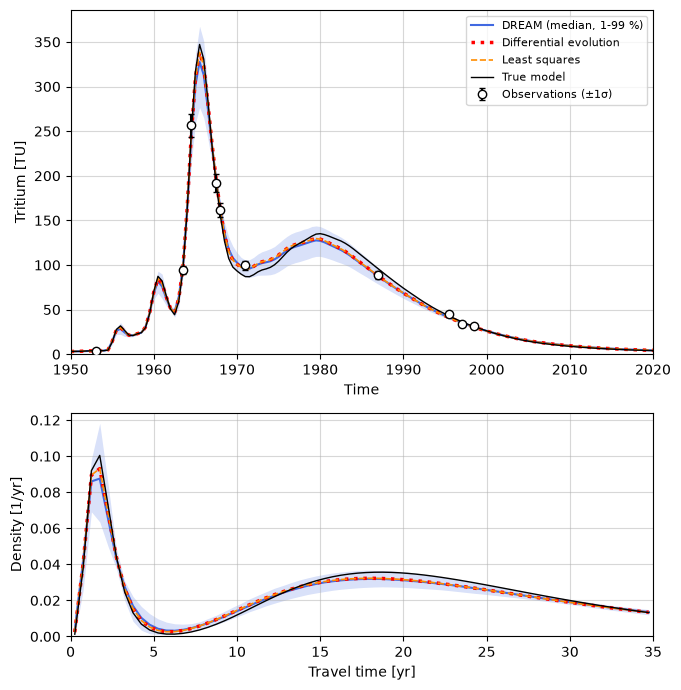

In [8]:
def total_ttd(model, values, n_steps=71):
    """Travel time distribution of the mixture (1/yr) for the first n_steps time steps."""
    for key, val in values.items():
        if key in model.params:
            model.set_param(key, val)
    ttds = model.get_ttds(n_steps=n_steps)
    h = sum(f * d for f, d in zip(ttds["fractions"], ttds["distributions"]))
    return h[1:] / DT


q = np.quantile(dream["sims"].reshape(-1, n), [0.01, 0.5, 0.99], axis=0)
tau = (np.arange(1, 71) - 0.5) * DT  # bin centres, 0-35 yr
draws = dream["samples"][np.random.default_rng(0).choice(len(dream["samples"]), 1000)]
tt = np.array([total_ttd(m, dict(zip(dream["param_names"], d))) for d in draws])
qt = np.quantile(tt, [0.01, 0.5, 0.99], axis=0)

fig, ax = plt.subplots(2, 1, figsize=(7, 7), gridspec_kw={"height_ratios": [2, 1.3]})
ax[0].fill_between(t_years[w], q[0, w], q[2, w], color="royalblue", alpha=0.2, lw=0)
ax[0].plot(t_years[w], q[1, w], c="royalblue", lw=1.5, label="DREAM (median, 1-99 %)")
ax[0].plot(t_years[w], de_sim[w], c="red", ls=":", lw=2.5, label="Differential evolution")
ax[0].plot(t_years[w], lsq_sim[w], c="darkorange", ls="--", lw=1.2, label="Least squares")
ax[0].plot(t_years[w], sim_true[w], c="k", lw=1.0, label="True model")
ax[0].errorbar(t_years[idx], obs[idx], yerr=NOISE_REL * obs[idx], fmt="o", mfc="w", mec="k",
               ecolor="k", capsize=2, zorder=10, label="Observations (±1σ)")
ax[0].set(xlim=(1950, 2020), ylim=(0, None), xlabel="Time", ylabel="Tritium [TU]")
ax[0].legend(fontsize=8)
ax[1].fill_between(tau, qt[0], qt[2], color="royalblue", alpha=0.2, lw=0)
ax[1].plot(tau, qt[1], c="royalblue", lw=1.5)
ax[1].plot(tau, total_ttd(m, de_x), c="red", ls=":", lw=2.5)
ax[1].plot(tau, total_ttd(m, lsq_x), c="darkorange", ls="--", lw=1.2)
ax[1].plot(tau, total_ttd(true_model, TRUE), c="k", lw=1.0)
ax[1].set(xlim=(0, 35), ylim=(0, None), xlabel="Travel time [yr]", ylabel="Density [1/yr]")
for a in ax:
    a.grid(True, alpha=0.5)
fig.tight_layout()
plt.show()

The posterior samples of DREAM show the uncertainty of each parameter (diagonal) and
the correlation between parameters (below the diagonal). The dashed lines mark the
true values.

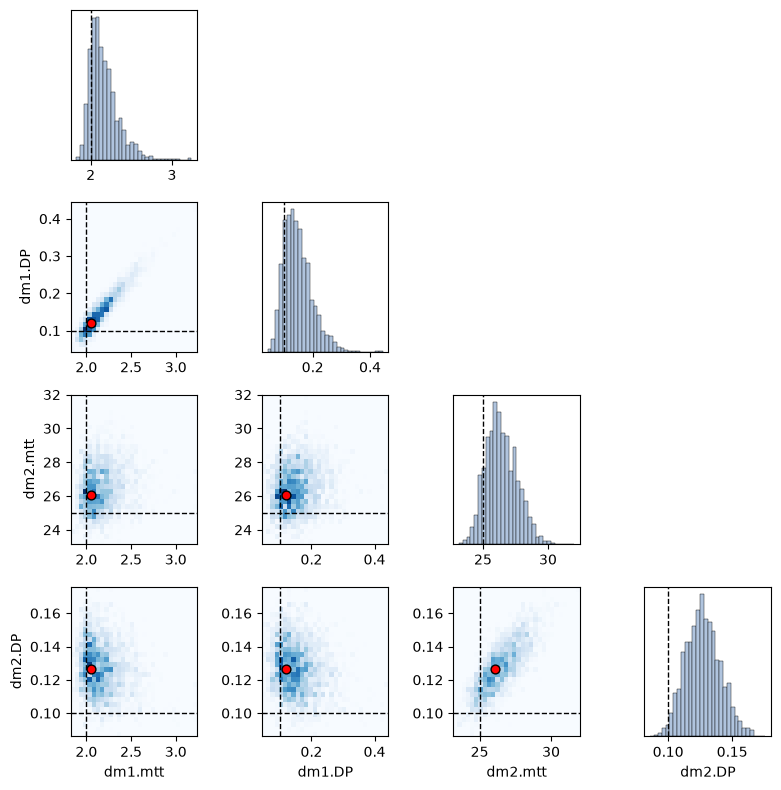

In [9]:
def corner(res, order, truth, best=None):
    """Marginal (diagonal) and pairwise (lower triangle) histograms of MCMC samples."""
    s = res["samples"][:, [res["param_names"].index(k) for k in order]]
    d = len(order)
    fig, axes = plt.subplots(d, d, figsize=(2 * d, 2 * d))
    for i in range(d):
        for j in range(d):
            ax = axes[i, j]
            if j > i:
                ax.axis("off")
                continue
            if i == j:
                ax.hist(s[:, i], bins=30, color="lightsteelblue", edgecolor="k", lw=0.3)
                ax.axvline(truth[order[i]], c="k", ls="--", lw=1.0)
                ax.set_yticks([])
            else:
                ax.hist2d(s[:, j], s[:, i], bins=30, cmap="Blues")
                ax.axvline(truth[order[j]], c="k", ls="--", lw=1.0)
                ax.axhline(truth[order[i]], c="k", ls="--", lw=1.0)
                if best is not None:
                    ax.scatter(best[order[j]], best[order[i]], c="r", edgecolor="k", s=40, zorder=10)
            if i == d - 1:
                ax.set_xlabel(order[j])
            if j == 0 and i > 0:
                ax.set_ylabel(order[i])
    fig.tight_layout()
    plt.show()


corner(dream, ["dm1.mtt", "dm1.DP", "dm2.mtt", "dm2.DP"], TRUE, best=de_x)  # red: DE

## 7. Calibrating the Mixing Fraction as Well

In a binary mixture, the mixing fraction can be calibrated together with the
parameters of both units (`m.set_fixed("dm1.fraction", False)`). The bounds of the
fraction (0-0.5) make unit 1 the smaller component, so that the two units cannot
swap roles. With five free parameters, the run uses more chains (10), a longer
burn-in (4000 steps) and more samples (6000 per chain).

R-hat: {'dm1.DP': 1.011, 'dm1.fraction': 1.006, 'dm1.mtt': 1.011, 'dm2.DP': 1.006, 'dm2.mtt': 1.004}
Outlier chains moved during burn-in: 5
dm1.DP        true  0.10   median  0.142  [1-99 %:  0.066,  0.293]
dm1.fraction  true  0.20   median  0.197  [1-99 %:  0.182,  0.213]
dm1.mtt       true  2.00   median  2.111  [1-99 %:  1.899,  2.707]
dm2.DP        true  0.10   median  0.128  [1-99 %:  0.098,  0.161]
dm2.mtt       true 25.00   median 26.255  [1-99 %: 23.891, 29.419]


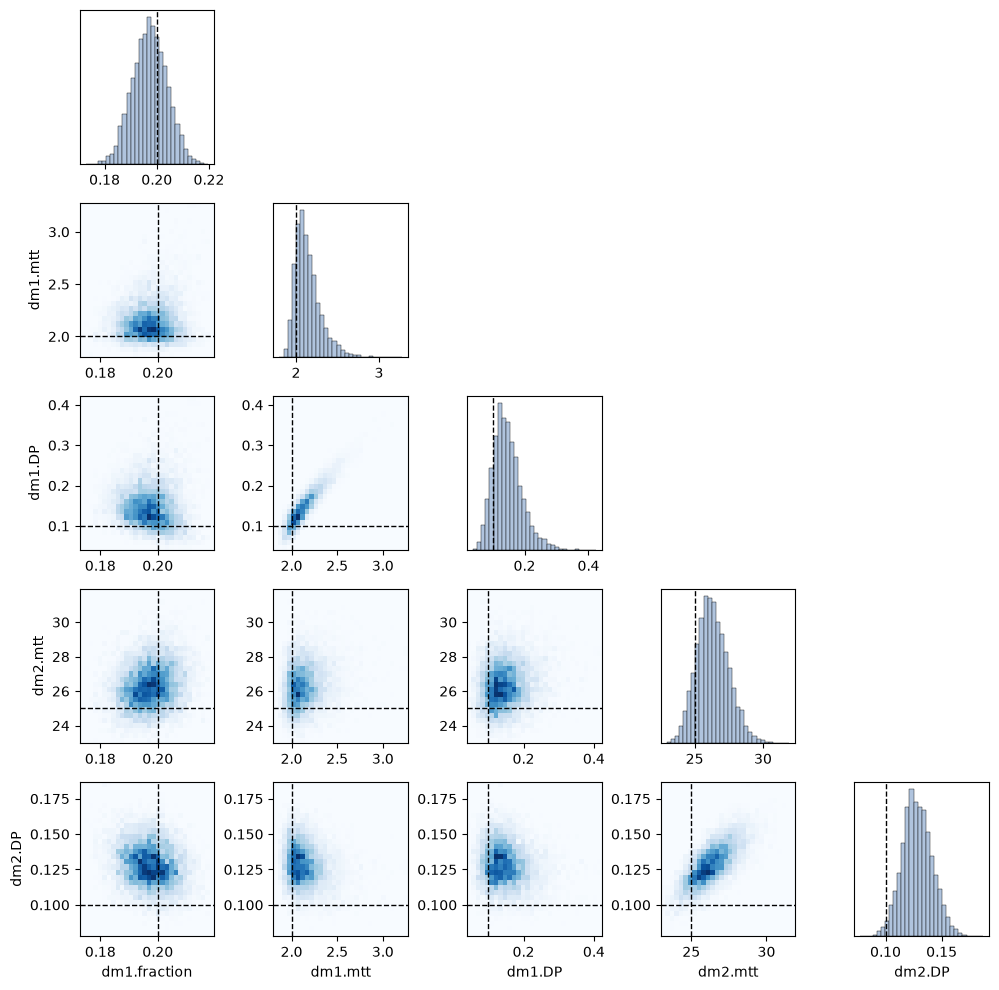

In [10]:
m_f = make_model(target=obs, free_fraction=True)
dream_f = lab.Solver(m_f).dream_sample(
    **{**dream_kw, "n_chains": 10, "burn_in": 4000, "n_samples": 6000}, sigma_rel=NOISE_REL
)
print("R-hat:", {k: round(float(v), 3) for k, v in dream_f["gelman_rubin"].items()})
print("Outlier chains moved during burn-in:", dream_f["n_outlier_resets"])
for k in m_f.param_keys(free_only=True):
    q = quantiles(dream_f, k)
    print(f"{k:13s} true {TRUE[k]:5.2f}   median {q[1]:6.3f}  [1-99 %: {q[0]:6.3f}, {q[2]:6.3f}]")
corner(dream_f, ["dm1.fraction", "dm1.mtt", "dm1.DP", "dm2.mtt", "dm2.DP"], TRUE)

In this example, the ten observations cover the bomb peak and have an uncertainty of
5 %, so the mixing fraction is well determined and hardly correlated with the other
parameters; the strongest correlations are between the mean travel time and the
dispersion parameter of each unit. With fewer observations or a less informative
tracer record, the mixing fraction and the mean travel times are often correlated
(as in Paper Example 4), and it can be better to fix one of them (see the user guide
on mixing fractions).

## Further Reading

- Tutorial 2 shows MCMC with a single unit and synthetic data.
- The user guide explains the measurement uncertainty options (`sigma`,
  `sigma_rel`, `_sd` columns in the observation file), mixing fractions and how to
  choose a solver.